# CS781 Phase 7 - Prior Case Retrieval
## Data preparation, retrieval checks and timing

This notebook prepares the official query and candidate pools before the four PCR training runs. It preserves the original case IDs, builds a reusable legal-BPE cache, measures a BM25 baseline, and checks the Phase 1-derived retrieval encoders.

The planned experiments are decoder partial fine-tuning, encoder-decoder IA³, prefix LoRMA+, and an efficient-derived distilled student. GPU probes use temporary model instances whose weights are discarded. They do not produce a trained submission.

The training-loop allowance is five hours per model. Candidate-pool encoding is measured separately so that validation and final export can be budgeted explicitly.


### Kaggle inputs

Use this notebook to create `phase7_pcr_prepared_data.zip` for the dense training and full-text reranking notebooks.


### Fresh Kaggle session

Select **GPU T4 x2** and attach the original **prep-2 tokenizer** plus the four **Phase 1 checkpoint datasets**. Enable Internet for the official PCR download. For a gated dataset, enable a Kaggle secret named `HF_TOKEN` after accepting dataset access on Hugging Face.

Alternatively, attach the six official `Phase_7_PCR` files with the Train/Dev/Test layout. The optional official `evaluate_phase7.py` can be attached for metric agreement checks. Its status remains visible when absent.

The source bundle is included in this notebook. A separate source dataset is unnecessary.


In [1]:
from pathlib import Path

INPUT_ROOT = Path('/kaggle/input')
PROJECT_ROOT = Path('/kaggle/working/cs781_phase7')
PROJECT_CODE_ROOT = PROJECT_ROOT / 'code'

# Set an input path only when discovery is ambiguous.
LOCAL_PCR_INPUT = None
PREPARED_INPUT = None
TOKENIZER_INPUT = None
EVALUATOR_INPUT = None
CHECKPOINT_INPUTS = {
    'decoder': None,
    'encoder_decoder': None,
    'prefix': None,
    'efficient': None,
}

RUN_GPU_CHECKS = True
STAGE_CHECKPOINTS = True
DEVICE = 'cuda:0'
REQUIRE_TWO_GPUS = True
AMP = True
WINDOW_TOKENS = 512
WINDOW_OVERLAP = 64
MAX_CHUNKS = 4
QUERY_BATCH_SIZE = 8
EFFECTIVE_QUERY_BATCH = 16
MAX_RUN_HOURS = 5.0
MODEL_SETTINGS_OVERRIDES = {}


## 1. Project source and dependencies

The bundled source contains the inherited native Transformer definitions and the PCR modules. Its digest and individual file identities are verified before use. Readable modules are also included in the companion GitHub package.


In [2]:
import base64
import hashlib
import io
import json
import zipfile

SOURCE_ARCHIVE_B64 = '...'
source_bytes = base64.b64decode(SOURCE_ARCHIVE_B64)
if hashlib.sha256(source_bytes).hexdigest() != '2228c1ee6942569abf965e015caef0ac60e43c2c0217d45f6a6a754de28f1d5c':
    raise ValueError('The embedded source archive differs from its recorded identity.')

PROJECT_CODE_ROOT.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(io.BytesIO(source_bytes)) as archive:
    manifest = json.loads(archive.read('source_manifest.json'))
    for name, expected in manifest['sha256'].items():
        target = (PROJECT_CODE_ROOT / name).resolve()
        if not target.is_relative_to(PROJECT_CODE_ROOT.resolve()):
            raise ValueError('Unexpected source path.')
        payload = archive.read(name)
        if hashlib.sha256(payload).hexdigest() != expected:
            raise ValueError('Source identity failed: ' + name)
        target.parent.mkdir(parents=True, exist_ok=True)
        if target.is_file() and target.read_bytes() != payload:
            raise ValueError('Working source differs. Preserve it and use a fresh PROJECT_ROOT: ' + name)
        target.write_bytes(payload)
    (PROJECT_CODE_ROOT / 'source_manifest.json').write_text(json.dumps(manifest, indent=2))

print('Project:', PROJECT_ROOT)
print('Source version:', manifest['version'])


Project: /kaggle/working/cs781_phase7
Source version: 1.0.0


In [3]:
import importlib.util
import subprocess
import sys

needed = ['numpy', 'pandas', 'scipy', 'matplotlib']
attached_raw = any(p.parent.name == 'Train' for p in INPUT_ROOT.rglob('train_candidates.json'))
attached_prepared = any(INPUT_ROOT.rglob('phase7_pcr_prepared_data.zip')) or any(
    p.parent.name == 'phase7_pcr_prepared' for p in INPUT_ROOT.rglob('bundle_manifest.json')
)
local_cache = (PROJECT_ROOT / 'prepared/cache/manifest.json').is_file()
if not any((LOCAL_PCR_INPUT, PREPARED_INPUT, attached_raw, attached_prepared, local_cache)):
    needed.append('huggingface_hub')
missing = [name for name in needed if importlib.util.find_spec(name) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
if importlib.util.find_spec('torch') is None:
    raise RuntimeError('Use a Kaggle PyTorch image for the native model checks.')

sys.path.insert(0, str(PROJECT_CODE_ROOT / 'src'))
import pandas as pd
from IPython.display import display, FileLink
from common import read_json, write_json
from pcr_prepare import (
    prepare_data, prepare_lexical, prepare_tokens, resolve_checkpoints,
    evaluator_check, run_probes, budget_records, export_outputs,
)

CONFIG = read_json(PROJECT_CODE_ROOT / 'configs/preparation_defaults.json')
CONFIG.update(
    project_root=str(PROJECT_ROOT), input_root=str(INPUT_ROOT),
    local_pcr_input=LOCAL_PCR_INPUT, prepared_input=PREPARED_INPUT,
    tokenizer_input=TOKENIZER_INPUT, evaluator_input=EVALUATOR_INPUT,
    checkpoint_inputs=CHECKPOINT_INPUTS, stage_checkpoints=STAGE_CHECKPOINTS,
    device=DEVICE, require_two_gpus=REQUIRE_TWO_GPUS, amp=AMP,
    query_batch_size=QUERY_BATCH_SIZE, effective_queries=EFFECTIVE_QUERY_BATCH,
    max_run_hours=MAX_RUN_HOURS,
)
CONFIG['geometry'].update(total_tokens=WINDOW_TOKENS, overlap=WINDOW_OVERLAP, max_chunks=MAX_CHUNKS)
CONFIG['model_settings'].update(MODEL_SETTINGS_OVERRIDES)
if not 0 <= WINDOW_OVERLAP < WINDOW_TOKENS - 2:
    raise ValueError('Overlap must be smaller than the content budget per window.')
if QUERY_BATCH_SIZE < 2 or EFFECTIVE_QUERY_BATCH < QUERY_BATCH_SIZE:
    raise ValueError('Use at least two queries per physical batch and a valid effective batch.')
print('Architectures:', ', '.join(CONFIG['architectures']))
print('Document windows:', MAX_CHUNKS, 'x', WINDOW_TOKENS)
print('Maximum training-loop allowance:', MAX_RUN_HOURS, 'hours')


Architectures: decoder, encoder_decoder, prefix, efficient
Document windows: 4 x 512
Maximum training-loop allowance: 5.0 hours


## 2. Official query and candidate audit

Each split has its own candidate pool. Relevance IDs are checked against that pool, and string IDs retain their leading zeros. Sentence-list text is joined with newlines. The audit records relevance-set sizes, repeated text and cross-split overlap.

Micro-F1@7 compares seven predictions with the complete gold set. The attainable ceiling accounts for queries with fewer or more than seven relevant cases; gold lists are not truncated or padded.


In [4]:
documents, data_manifest, data_audit = prepare_data(CONFIG)
display(pd.DataFrame(data_audit['splits']))
display(pd.DataFrame(data_audit['overlaps']))
print('Data revision:', data_manifest.get('revision') or 'attached official files')
print('Training queries with positives:', data_audit['training_queries_with_positives'])


Phase_7_PCR/Train/train.json: reconstructing file:   0%|          |  0.00B / 33.2MB            

Phase_7_PCR/Train/train.json: downloading bytes:           |  0.00B            

Phase_7_PCR/Train/train_candidates.json: reconstructing file:   0%|          |  0.00B /  160MB            

Phase_7_PCR/Train/train_candidates.json: downloading bytes:           |  0.00B            

dev.json:   0%|          | 0.00/5.87M [00:00<?, ?B/s]

Phase_7_PCR/Dev/dev_candidates.json: reconstructing file:   0%|          |  0.00B / 51.9MB            

... (3 outputs left out)

Phase_7_PCR/Test/test_candidates.json: downloading bytes:           |  0.00B            

,split,queries,candidates,relevance_links,empty_relevance_queries,mean_relevant_per_query,median_relevant_per_query,max_relevant_per_query,attainable_micro_f1_at_7,same_id_query_candidate,mean_query_characters,mean_candidate_characters
0,train,827,4320,5308.0,10.0,6.418380,4.0,52.0,0.638551,827,39344.604595,36421.706481
1,dev,118,1023,973.0,0.0,8.245763,5.0,92.0,0.618121,118,48739.584746,49977.323558
2,test,237,1727,NaN,NaN,NaN,NaN,NaN,NaN,237,38781.118143,40553.928199


,left,right,common_ids,right_rows_matching_exact_text,right_rows_matching_normalized_text
0,train_query,train_candidate,827,829,829
1,train_query,dev_query,0,0,0
2,train_query,dev_candidate,124,124,124
3,train_query,test_query,0,1,1
4,train_query,test_candidate,269,270,270
5,train_candidate,dev_query,90,90,90
6,train_candidate,dev_candidate,436,437,437
7,train_candidate,test_query,170,171,171
8,train_candidate,test_candidate,740,742,742
9,dev_query,dev_candidate,118,118,118


Data revision: 93b0059be756c6c461f3a225de25aabda7d5f84a
Training queries with positives: 817


## 3. BM25 reference and training hard negatives

BM25 scores the complete candidate pool for each query using that split's documents. The lexical reference uses k1=1.2, b=0.75 and positive IDF. It is a baseline and a source of hard negatives, not one of the four trained neural experiments.

Training hard-negative lists exclude all known relevant IDs and exact copies of the query text. Other queries' candidates must also be checked against the current query's relevance set before being treated as negatives.


In [5]:
bm25_results = prepare_lexical(CONFIG, documents)
display(pd.DataFrame(bm25_results).T.reindex(columns=[
    'queries', 'candidates', 'micro_f1_at_7', 'micro_precision_at_7', 'micro_recall_at_7', 'seconds'
]))
print('BM25 predictions, sparse indexes and training hard negatives are saved.')


BM25 train: 1/827 queries
BM25 train: 101/827 queries
BM25 train: 201/827 queries
BM25 train: 301/827 queries
BM25 train: 401/827 queries
BM25 train: 501/827 queries
BM25 train: 601/827 queries
BM25 train: 701/827 queries
BM25 train: 801/827 queries
BM25 train: 827/827 queries
BM25 dev: 1/118 queries
BM25 dev: 101/118 queries
BM25 dev: 118/118 queries
BM25 test: 1/237 queries
BM25 test: 101/237 queries
BM25 test: 201/237 queries
BM25 test: 237/237 queries


,queries,candidates,micro_f1_at_7,micro_precision_at_7,micro_recall_at_7,seconds
train,827,4320,0.093899,0.089998,0.098154,32.151871
dev,118,1023,0.091162,0.099274,0.084275,6.399
test,237,1727,NaN,NaN,NaN,9.948443


BM25 predictions, sparse indexes and training hard negatives are saved.


## 4. Original legal BPE and packed tokens

I reuse the original 16,000-token prep-2 tokenizer without fitting new merges. Its state, signature, reserved IDs and round trips are verified.

Content tokens are packed into a memory-mapped binary array with per-document offsets. Committed rows can be reused after an interruption. BOS/EOS and padding are added by the collator. Four 512-position windows provide up to 510 content tokens each; adjacent candidate windows overlap by 64 content tokens.

The coverage comparison is a representation diagnostic, not an accuracy ablation.


In [6]:
token_lengths, chunk_coverage = prepare_tokens(CONFIG, documents, data_manifest)
display(token_lengths)
display(chunk_coverage)

del documents
import gc
gc.collect()


Token cache: 2,138/8,252 documents | 0.3 min
Token cache: 4,569/8,252 documents | 0.7 min
Token cache: 6,499/8,252 documents | 1.0 min
Token cache: 8,252/8,252 documents | 1.3 min


,split,role,documents,tokens_p0,tokens_p25,tokens_p50,tokens_p75,tokens_p90,tokens_p95,tokens_p99,tokens_p100
0,train,query,827,311.0,6014.50,10384.0,17632.50,28818.2,46950.8,102432.84,283253.0
1,train,candidate,4320,10.0,4396.50,8280.0,15450.25,28366.7,44635.9,111203.17,957200.0
2,dev,query,118,1292.0,5983.25,10607.5,18634.25,35372.1,46270.9,230805.72,246842.0
3,dev,candidate,1023,78.0,4847.00,9229.0,17283.50,38186.4,62308.8,194116.98,957200.0
4,test,query,237,257.0,5405.00,10574.0,18276.00,31965.4,45381.4,68355.52,210315.0
5,test,candidate,1727,92.0,4712.50,8988.0,17187.00,31463.4,48592.1,141429.18,957200.0


,split,role,policy,mean_chunks,mean_content_coverage
0,train,query,uniform,3.972189,0.242770
1,train,query,head,3.972189,0.247933
2,train,query,tail,3.972189,0.221716
3,train,query,head_tail,3.972189,0.229046
4,train,candidate,uniform,3.903935,0.314902
5,train,candidate,head,3.903935,0.321958
6,train,candidate,tail,3.903935,0.292157
7,train,candidate,head_tail,3.903935,0.300541
8,dev,query,uniform,3.991525,0.226048
9,dev,query,head,3.991525,0.231458


0

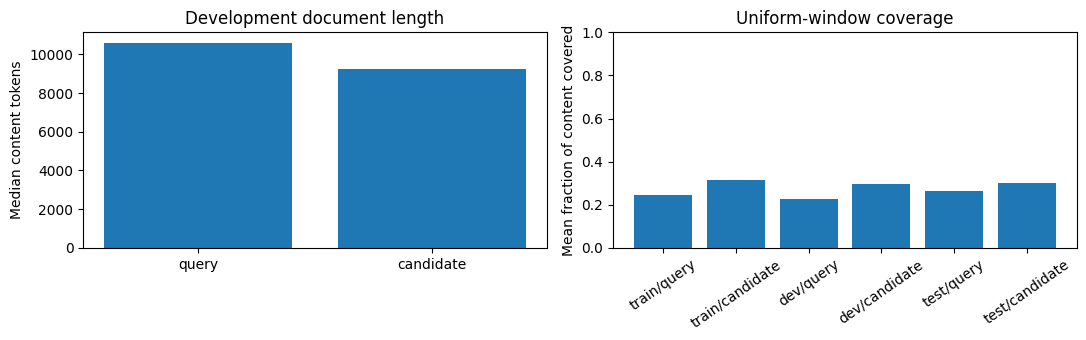

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
dev_lengths = token_lengths[token_lengths['split'] == 'dev']
axes[0].bar(dev_lengths['role'], dev_lengths['tokens_p50'])
axes[0].set(title='Development document length', ylabel='Median content tokens')
uniform = chunk_coverage[chunk_coverage['policy'] == 'uniform'].copy()
uniform['group'] = uniform['split'] + '/' + uniform['role']
axes[1].bar(uniform['group'], uniform['mean_content_coverage'])
axes[1].tick_params(axis='x', rotation=35)
axes[1].set(title='Uniform-window coverage', ylabel='Mean fraction of content covered', ylim=(0, 1))
fig.tight_layout()
figure_dir = PROJECT_ROOT / 'reports/figures'
figure_dir.mkdir(exist_ok=True)
fig.savefig(figure_dir / 'document_coverage.png', dpi=150, bbox_inches='tight')
plt.show()


## 5. Top-seven contract and evaluator agreement

Predictions map each query ID to seven distinct candidate-ID strings, sorted by relevance. The local implementation counts hits across queries and uses all supplied gold relevance links.

If the official evaluator is attached, its CLI output is checked against the dev BM25 reference. A missing evaluator remains `not_attached`; an incompatible interface remains `review_needed`. Neither is reported as official agreement.


In [8]:
evaluation_check = evaluator_check(CONFIG)
print('Internal top-seven checks:', evaluation_check['internal_status'])
print('Official evaluator:', evaluation_check['official_status'])
display(pd.Series(evaluation_check['internal_metrics']))
if evaluation_check['official_status'] == 'review_needed':
    print('See reports/evaluator_check.json for the script interface and output.')


Internal top-seven checks: passed
Official evaluator: review_needed


micro_f1_at_7           0.091162
micro_precision_at_7    0.099274
micro_recall_at_7       0.084275
dtype: float64

See reports/evaluator_check.json for the script interface and output.


## 6. Small mathematical checks

These CPU fixtures check multi-positive contrastive loss, complete gold-set counting, IA³ identity, LoRMA+ matrix equivalence and candidate-distribution KL. They do not measure legal retrieval quality or create a teacher cache.


In [9]:
from pcr_validation import run_math_checks

mathematical_checks = run_math_checks()
write_json(PROJECT_ROOT / 'reports/mathematical_checks.json', mathematical_checks)
display(pd.Series(mathematical_checks))


ia3_identity_and_output_scaling                         passed
ia3_ffn_identity                                        passed
lorma_identity_and_multiplicative_matrix_equivalence    passed
multi_positive_contrastive_loss                         passed
candidate_softmax_kl_and_detached_teacher               passed
micro_f1_at_7_complete_gold_sets                        passed
chunk_bounds_and_uniform_selection                      passed
dtype: object

## 7. Original Phase 1 checkpoint inputs

The four original checkpoints are matched to their recorded Phase 1 identities. Optional sequential staging places verified copies on working storage. Original weights remain separate from the prepared-data export.

The compact efficient encoder retains original blocks [0, 7, 15]. No Phase 5 task checkpoint or teacher cache is needed here.


In [10]:
input_table = resolve_checkpoints(CONFIG)
display(input_table[['architecture', 'original_run', 'bytes', 'byte_identity', 'path']])


Verifying original Phase 1 checkpoint: decoder
Verifying original Phase 1 checkpoint: encoder_decoder
Verifying original Phase 1 checkpoint: prefix
Verifying original Phase 1 checkpoint: efficient


,architecture,original_run,bytes,byte_identity,path
0,decoder,decoder_004_mixed217m,871513977,passed,/kaggle/working/cs781_phase7/staged_checkpoint...
1,encoder_decoder,encdec_002_mixed217m_stable,871503069,passed,/kaggle/working/cs781_phase7/staged_checkpoint...
2,prefix,prefix_001_mixed217m,871521847,passed,/kaggle/working/cs781_phase7/staged_checkpoint...
3,efficient,efficient,871562425,passed,/kaggle/working/cs781_phase7/staged_checkpoint...


## 8. Retrieval encoder, memory and timing probes

Queries and candidates share one document encoder. Native chunk readouts feed a projection, BiGRU, chunk attention and a normalized retrieval vector. Adaptation uses upper-layer partial fine-tuning, IA³, LoRMA+, or a fully trainable compact backbone.

Each architecture runs in an isolated process. The probe checks maximum-shape memory with optimizer and EMA storage, real-case embedding/gradient agreement, then accumulated retrieval updates. Timing uses zero learning rates and excludes the warmup update. Query accumulation does not enlarge the in-batch negative pool.

Query/candidate inference samples estimate pool-encoding costs. A six-step short-window learning check then uses temporary weights, which are discarded. Efficient timing measures the compact architecture with gold ranking loss; later KD scoring and teacher export are separate costs.


In [11]:
if RUN_GPU_CHECKS:
    timing_table = run_probes(CONFIG)
else:
    timing_table = pd.DataFrame()
    print('Data-only preparation: full model/GPU probes have not run.')
display(timing_table)
if not timing_table.empty and (timing_table['status'] == 'failed').any():
    print('Review the selected probe JSON and log for failed architectures before training.')


Checking decoder: 8 queries/microbatch, 64 chunks/GPU call
Loading the verified original checkpoint: decoder
Checking maximum-shape memory with optimizer state
Checking real-case embeddings and shared-loss gradients
/kaggle/working/cs781_phase7/code/src/pcr_probe.py:99: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:836.)
  finite_embeddings=True,unit_norm_max_error=float((parallel['embeddings'].norm(dim=1)-1).abs().max()),
Measuring accumulated retrieval updates
Measuring query and candidate encoding rates
Checking temporary short-window learning; these weights will be discarded
Probe status: passed
decoder probe status: passed
Checking encoder_decoder: 8 queries/microbatch, 64 chunks/GPU call
Loading the verified original checkpoint: encoder_decoder
Checking maximum-shape memory with optimizer state
Ch

,architecture,status,total_parameters,trainable_parameters,query_batch_size,accumulation,effective_queries,seconds_per_update,estimated_epoch_minutes,estimated_full_dev_minutes,estimated_test_encode_minutes,peak_reserved_gib
0,decoder,passed,218763904,26090112,8,2,16,2.959451,2.518616,0.616483,1.059038,4.576172
1,encoder_decoder,passed,218858112,1002112,8,2,16,5.041644,4.290649,0.502489,0.869426,8.183594
2,prefix,passed,221125248,3263104,8,2,16,10.649168,9.062885,0.986499,1.727715,9.429688
3,efficient,passed,55068544,55068544,8,2,16,2.327501,1.980800,0.180583,0.305718,4.537109


## 9. Five-hour budget interpretation

The proposal reserves three projected full-dev encodings and ten minutes for saving/metrics within the five-hour loop. Full vector ranking, metric computation and disk work add to the encoding estimate, so the update proposal is provisional. Final test encoding, preparation and teacher export are separate costs.

A model with no useful update budget after the reserve needs a geometry or validation-schedule adjustment. These are throughput measurements and extrapolations, not trained results.


In [12]:
budget_table = budget_records(CONFIG)
display(budget_table)
if budget_table.empty:
    print('No successful probes are available for a training-budget estimate.')


,architecture,status,proposed_optimizer_updates,effective_queries,estimated_equivalent_query_epochs,reserved_full_dev_passes,estimated_dev_minutes,max_training_loop_hours,final_test_encoding_minutes,teacher_train_encoding_minutes,warning
0,decoder,measured_projection_not_training,5841,16,114.389229,3,0.616483,5.0,1.059038,2.658603,
1,encoder_decoder,measured_projection_not_training,3433,16,67.231334,3,0.502489,5.0,0.869426,2.222164,
2,prefix,measured_projection_not_training,1617,16,31.667075,3,0.986499,5.0,1.727715,4.363876,
3,efficient,measured_projection_not_training,7461,16,146.115055,3,0.180583,5.0,0.305718,0.771139,


## 10. Save reusable preparation and diagnostics

The prepared-data ZIP contains token arrays, row identities, split-specific BM25 indexes, hard negatives and reports. The smaller diagnostics ZIP contains source, checks and timing logs. Original model weights are not copied into either archive.

Both archives are verified before publication and have SHA-256 sidecars. Keep the prepared bundle for training and the diagnostics for experiment documentation. Neither is a trained PCR submission.


In [13]:
export_status = export_outputs(CONFIG)
display(pd.Series(export_status))
for name in ('prepared_data_zip', 'diagnostics_zip'):
    path = Path(export_status[name])
    display(FileLink(str(path)))
    display(FileLink(str(path) + '.sha256'))


prepared_data_zip                 /kaggle/working/phase7_pcr_prepared_data.zip
prepared_bytes                                                       192431589
prepared_sha256              165b619bfcccd1dd9a61c581f78d2ae79e488aacaabf5c...
diagnostics_zip              /kaggle/working/phase7_pcr_preparation_diagnos...
diagnostics_bytes                                                       198379
diagnostics_sha256           f93c7490bc4224cca64301a65ab53372829493e31f7076...
token_cache_rows                                                          8252
official_evaluator_status                                        review_needed
note                         Preparation artifacts only; no retrieval model...
dtype: object

/kaggle/working/phase7_pcr_prepared_data.zip

/kaggle/working/phase7_pcr_prepared_data.zip.sha256

/kaggle/working/phase7_pcr_preparation_diagnostics.zip

/kaggle/working/phase7_pcr_preparation_diagnostics.zip.sha256

### Next experiment stage

The training notebook will use the verified preparation and the matching original Phase 1 checkpoint. The first three runs establish the larger retrieval models. Their dev Micro-F1@7 results will determine the teacher for the compact KD run.

Candidate embeddings must be rebuilt from the selected checkpoint before full-pool retrieval. Final exports must cover every test query and use only the test candidate pool.

### References

- CS781 Capstone, Phase 7: Prior Case Retrieval.
- Karpukhin et al. (2020), [Dense Passage Retrieval](https://aclanthology.org/2020.emnlp-main.550/).
- Liu et al. (2022), [IA³](https://arxiv.org/abs/2205.05638).
- Native backbones, original tokenizer and shared Phase 5 readouts are identified in `SOURCE_PROVENANCE.json`.
